In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print("Environment initialized for Multi-Algorithm Benchmark Tournament!")


Environment initialized for Multi-Algorithm Benchmark Tournament!


In [8]:
DATASET_PATH = 'data/SYNTHETIC_DATASET_100_CLEANED.csv'
df = pd.read_csv(DATASET_PATH)

ignore_cols = ['id', 'Sound', 'Mtrue', 'TEtrue', 'Mhat_v01', 'TEhat_v01', 'Soundhat_v01', 'Mat']
feature_cols = [c for c in df.columns if c not in ignore_cols]
X = df[feature_cols]

print(f"Dataset shape: {df.shape[0]} samples x {len(feature_cols)} predictor features.")


Dataset shape: 100 samples x 43 predictor features.


In [9]:
candidate_models = {
    'Ridge (L2)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', Ridge(alpha=5.0))
    ]),
    'Lasso (L1)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', Lasso(alpha=0.1, random_state=42))
    ]),
    'ElasticNet': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42))
    ]),
    'SVR (RBF Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', SVR(C=10.0, epsilon=0.1))
    ]),
    'KNN Regressor': Pipeline([
        ('scaler', StandardScaler()),
        ('reg', KNeighborsRegressor(n_neighbors=5))
    ]),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, max_depth=4, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.08, random_state=42),
    'AdaBoost': AdaBoostRegressor(n_estimators=50, random_state=42)
}

print(f"Configured {len(candidate_models)} candidate algorithms across 4 model families.")


Configured 9 candidate algorithms across 4 model families.


In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
targets = {
    'Misalignment (M)': 'Mtrue',
    'Transmission Error (STE)': 'TEtrue',
    'Sound Power Level (LW)': 'Sound'
}

benchmark_records = []
predictions_store = {}

for target_name, target_col in targets.items():
    y = df[target_col]
    predictions_store[target_name] = {}
    
    for algo_name, model in candidate_models.items():
        preds = cross_val_predict(model, X, y, cv=cv)
        predictions_store[target_name][algo_name] = preds
        
        r2 = r2_score(y, preds)
        mae = mean_absolute_error(y, preds)
        rmse = root_mean_squared_error(y, preds)
        
        benchmark_records.append({
            'Target Output': target_name,
            'Algorithm': algo_name,
            'R² Score': round(r2, 4),
            'MAE': round(mae, 4),
            'RMSE': round(rmse, 4)
        })

df_all_benchmarks = pd.DataFrame(benchmark_records)
print("Tournament execution completed across all 9 algorithms and 3 target metrics!")


Tournament execution completed across all 9 algorithms and 3 target metrics!


In [11]:
for target_name in targets.keys():
    sub_df = df_all_benchmarks[df_all_benchmarks['Target Output'] == target_name].copy()
    sub_df = sub_df.sort_values(by='R² Score', ascending=False).reset_index(drop=True)
    sub_df['Rank'] = sub_df.index + 1
    cols = ['Rank', 'Algorithm', 'R² Score', 'MAE', 'RMSE']
    print(f"\n{'='*70}")
    print(f"LEADERBOARD: {target_name.upper()}")
    print(f"{'='*70}")
    display(sub_df[cols])



LEADERBOARD: MISALIGNMENT (M)


,Rank,Algorithm,R² Score,MAE,RMSE
0,1,Random Forest,0.9526,4.3506,5.1543
1,2,Gradient Boosting,0.9513,4.3510,5.2260
2,3,AdaBoost,0.9491,4.3826,5.3417
3,4,ElasticNet,0.9474,4.2895,5.4325
4,5,Lasso (L1),0.9461,4.0993,5.4963
5,6,Ridge (L2),0.9445,4.4331,5.5799
6,7,Extra Trees,0.9364,4.9436,5.9702
7,8,KNN Regressor,0.8267,7.7844,9.8571
8,9,SVR (RBF Kernel),0.8011,7.9394,10.5597



LEADERBOARD: TRANSMISSION ERROR (STE)


,Rank,Algorithm,R² Score,MAE,RMSE
0,1,Ridge (L2),0.8421,0.1769,0.2119
1,2,ElasticNet,0.6138,0.2596,0.3314
2,3,SVR (RBF Kernel),0.5463,0.2847,0.3592
3,4,Gradient Boosting,0.5134,0.2965,0.3720
4,5,AdaBoost,0.4605,0.3191,0.3917
5,6,Extra Trees,0.4212,0.3323,0.4057
6,7,Lasso (L1),0.4056,0.3298,0.4111
7,8,Random Forest,0.4024,0.3358,0.4122
8,9,KNN Regressor,0.2876,0.3654,0.4501



LEADERBOARD: SOUND POWER LEVEL (LW)


,Rank,Algorithm,R² Score,MAE,RMSE
0,1,Lasso (L1),0.8769,1.5341,2.0076
1,2,ElasticNet,0.8728,1.6179,2.0413
2,3,Ridge (L2),0.8707,1.6554,2.0582
3,4,Extra Trees,0.6450,2.8277,3.4097
4,5,SVR (RBF Kernel),0.6427,2.7485,3.4208
5,6,Gradient Boosting,0.5984,2.9437,3.6266
6,7,Random Forest,0.5984,2.9865,3.6270
7,8,AdaBoost,0.5699,3.0380,3.7533
8,9,KNN Regressor,0.4056,3.5852,4.4122


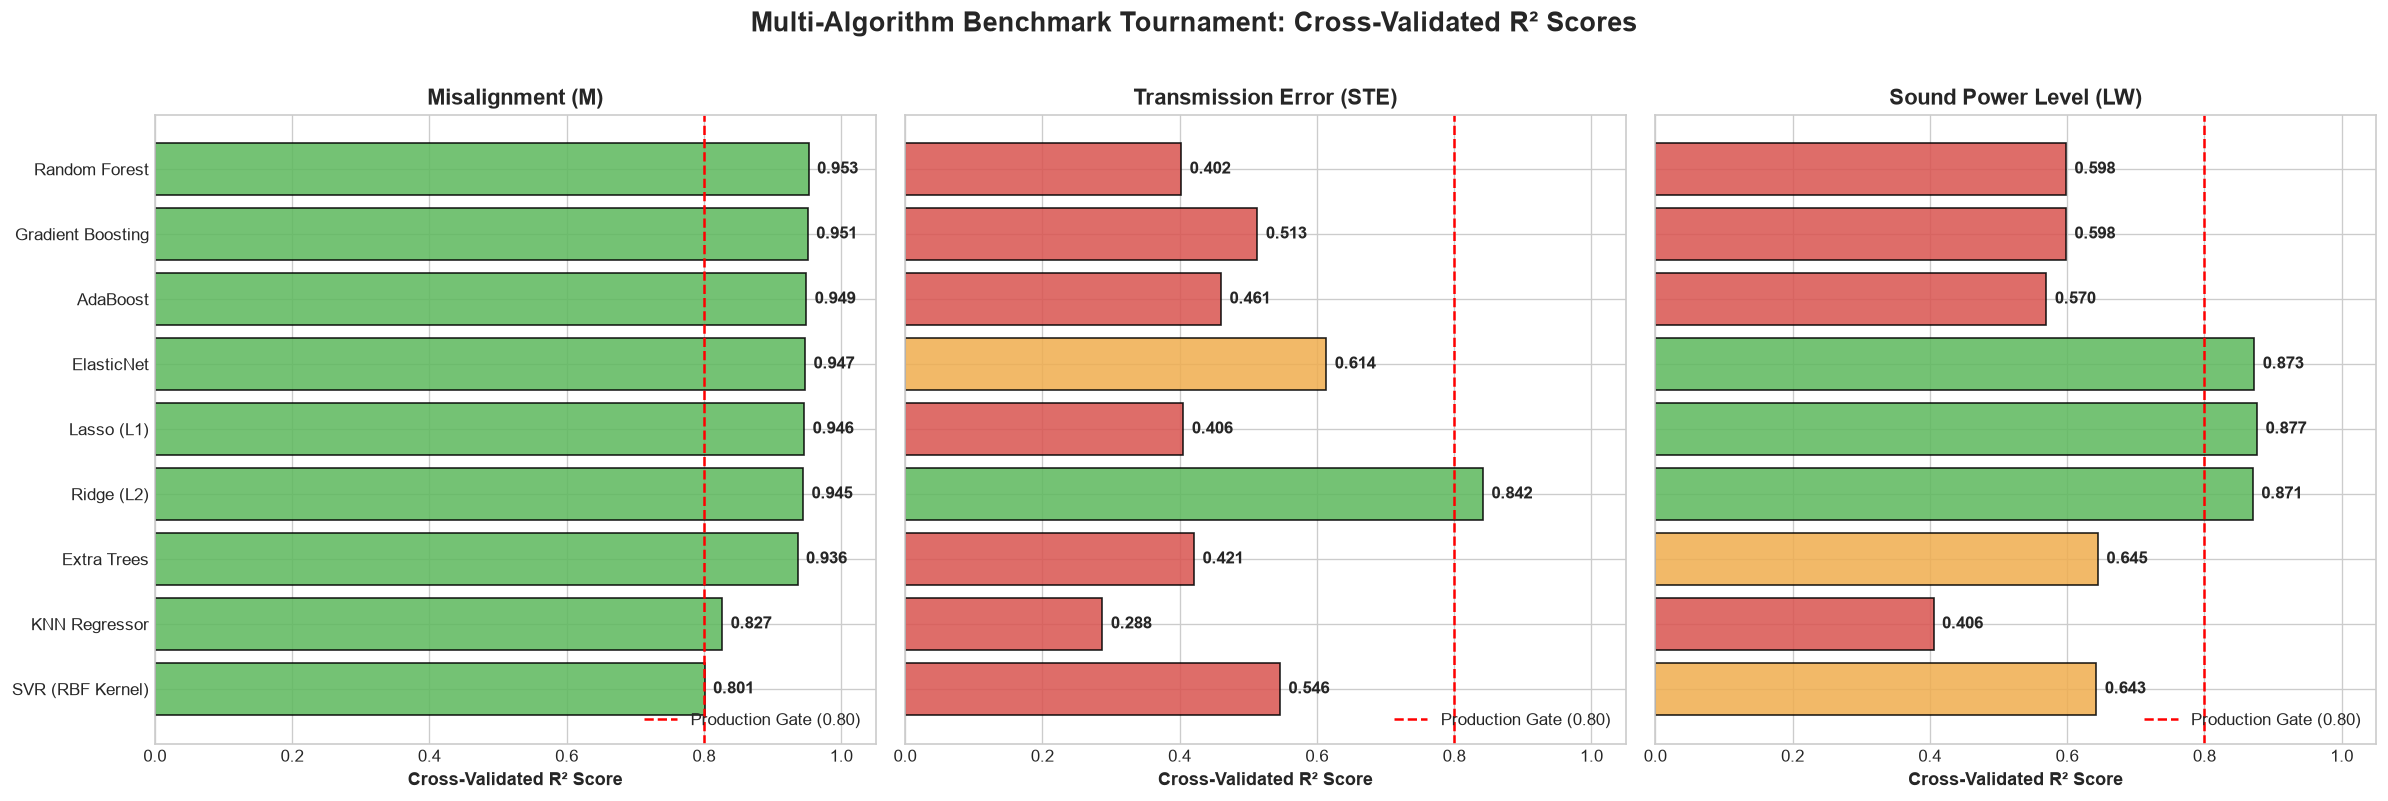

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)

for idx, (target_name, ax) in enumerate(zip(targets.keys(), axes)):
    sub_df = df_all_benchmarks[df_all_benchmarks['Target Output'] == target_name].sort_values(by='R² Score', ascending=True)
    
    colors = ['#d9534f' if r < 0.6 else '#f0ad4e' if r < 0.8 else '#5cb85c' for r in sub_df['R² Score']]
    bars = ax.barh(sub_df['Algorithm'], sub_df['R² Score'], color=colors, edgecolor='black', alpha=0.85)
    
    ax.set_title(f'{target_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Cross-Validated R² Score', fontsize=11, fontweight='bold')
    ax.set_xlim(0.0, 1.05)
    ax.axvline(0.80, color='red', linestyle='--', label='Production Gate (0.80)')
    ax.legend(loc='lower right')
    
    for bar in bars:
        w = bar.get_width()
        ax.annotate(f'{w:.3f}', xy=(w, bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords="offset points",
                    ha='left', va='center', fontsize=10, fontweight='bold')

plt.suptitle('Multi-Algorithm Benchmark Tournament: Cross-Validated R² Scores', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('tournament_r2_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


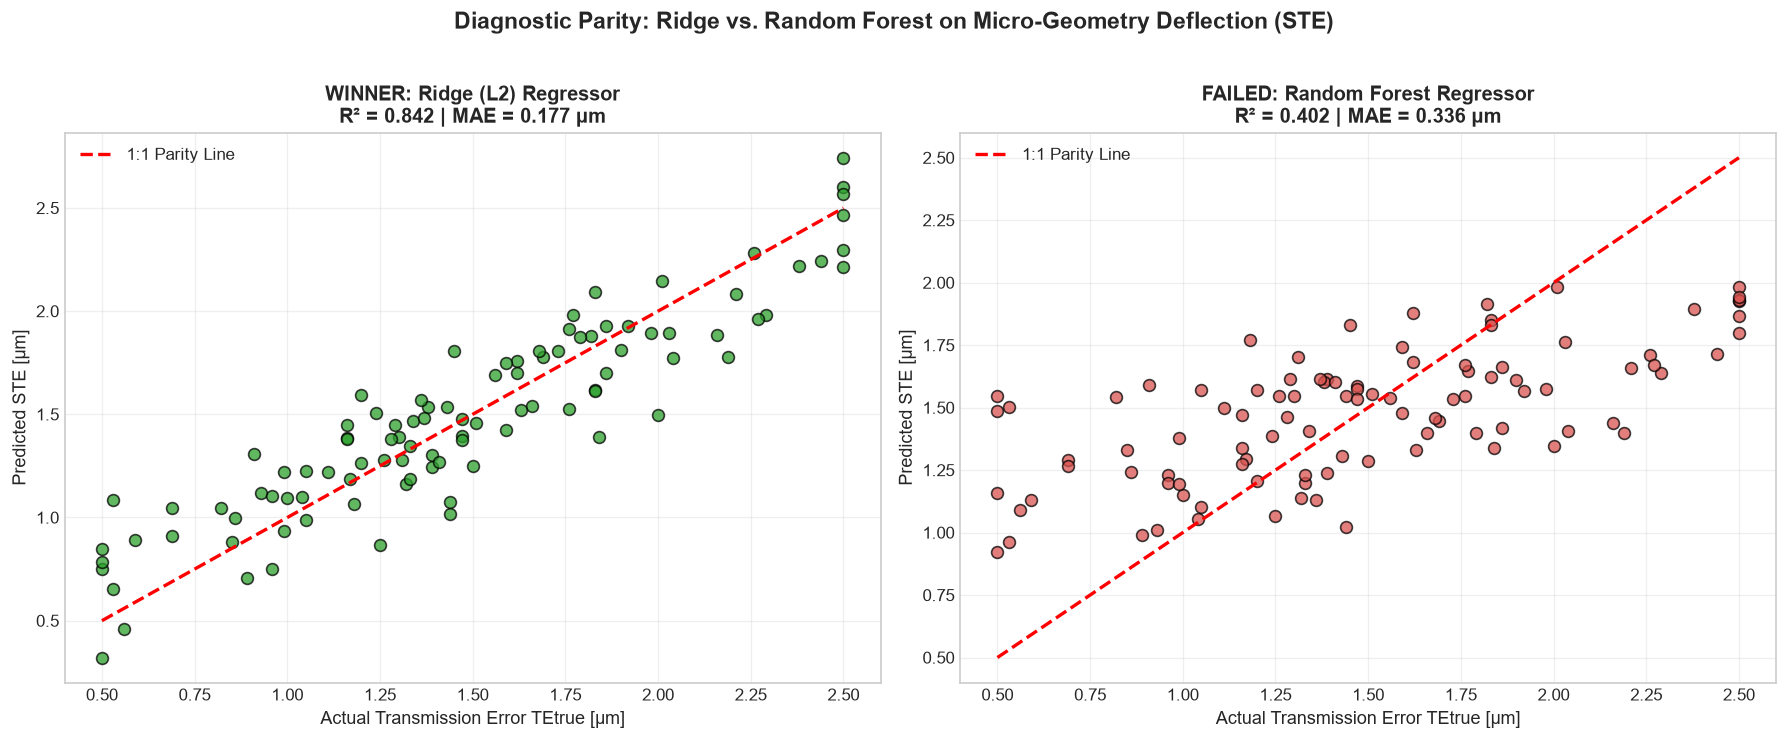

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

y_te = df['TEtrue']
pred_ridge = predictions_store['Transmission Error (STE)']['Ridge (L2)']
pred_rf = predictions_store['Transmission Error (STE)']['Random Forest']

# Ridge Plot
ax1.scatter(y_te, pred_ridge, color='#2ca02c', alpha=0.75, edgecolors='k', s=50)
ax1.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'r--', lw=2, label='1:1 Parity Line')
ax1.set_title(f'WINNER: Ridge (L2) Regressor\nR² = {r2_score(y_te, pred_ridge):.3f} | MAE = {mean_absolute_error(y_te, pred_ridge):.3f} µm', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Transmission Error TEtrue [µm]', fontsize=11)
ax1.set_ylabel('Predicted STE [µm]', fontsize=11)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Random Forest Plot
ax2.scatter(y_te, pred_rf, color='#d9534f', alpha=0.75, edgecolors='k', s=50)
ax2.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'r--', lw=2, label='1:1 Parity Line')
ax2.set_title(f'FAILED: Random Forest Regressor\nR² = {r2_score(y_te, pred_rf):.3f} | MAE = {mean_absolute_error(y_te, pred_rf):.3f} µm', fontsize=12, fontweight='bold')
ax2.set_xlabel('Actual Transmission Error TEtrue [µm]', fontsize=11)
ax2.set_ylabel('Predicted STE [µm]', fontsize=11)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Diagnostic Parity: Ridge vs. Random Forest on Micro-Geometry Deflection (STE)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('tournament_diagnostic_ridge_vs_rf.png', dpi=200, bbox_inches='tight')
plt.show()
